In [1]:
import site
import sys
import subprocess
import os

# 1. Registrar la ruta de paquetes del usuario en el sistema
user_site = '/headless/.local/lib/python3.12/site-packages'
if os.path.exists(user_site):
    site.addsitedir(user_site)

# 2. Intentar importar; si falla, instalarlo automáticamente
try:
    from PyLTSpice import RawRead
    print('¡PyLTSpice ya estaba instalado y listo para usar!')
except ImportError:
    print('PyLTSpice no fue encontrado. Instalando automáticamente...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--user', 'PyLTSpice'])
    if os.path.exists(user_site):
        site.addsitedir(user_site)
    from PyLTSpice import RawRead
    print('¡PyLTSpice se instaló e importó correctamente!')

¡PyLTSpice ya estaba instalado y listo para usar!


✅ Muestras extraídas por variable:
VR 100us (V)        5
VR 1ms (V)          5
VR 100ms (V)        5
IBIAS 100ms (uA)    5
dtype: int64

--- Primeros 5 datos ---
   VR 100us (V)  VR 1ms (V)  VR 100ms (V)  IBIAS 100ms (uA)
0      0.700531    0.700531      0.700531           11.3796
1      0.702846    0.702846      0.702846           11.4176
2      0.703342    0.703342      0.703342           11.4257
3      0.699490    0.699490      0.699490           11.3625
4      0.703472    0.703472      0.703472           11.4278

--- Resumen Estadístico ---
       VR 100us (V)  VR 1ms (V)  VR 100ms (V)  IBIAS 100ms (uA)
count      5.000000    5.000000      5.000000           5.00000
mean       0.701936    0.701936      0.701936          11.40264
std        0.001811    0.001811      0.001811           0.02971
min        0.699490    0.699490      0.699490          11.36250
max        0.703472    0.703472      0.703472          11.42780


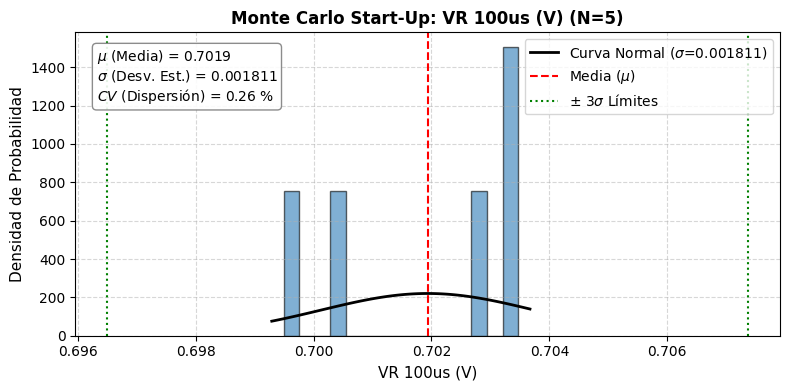

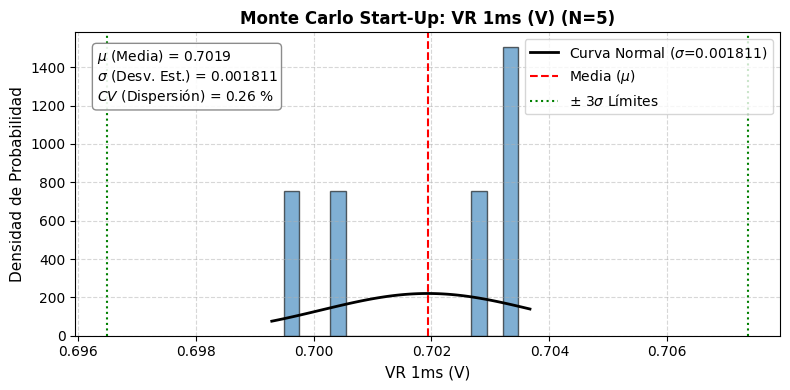

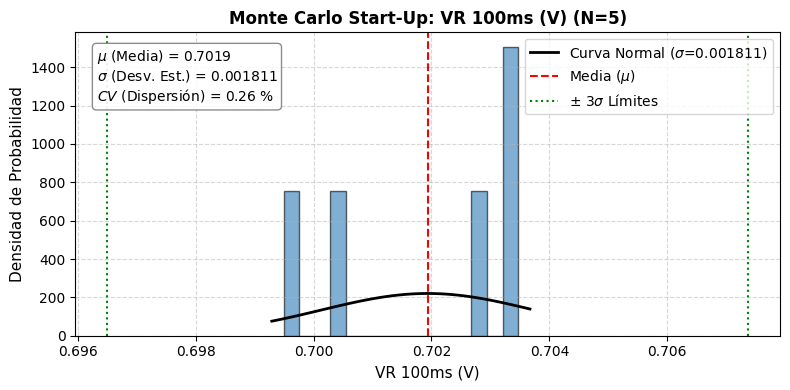

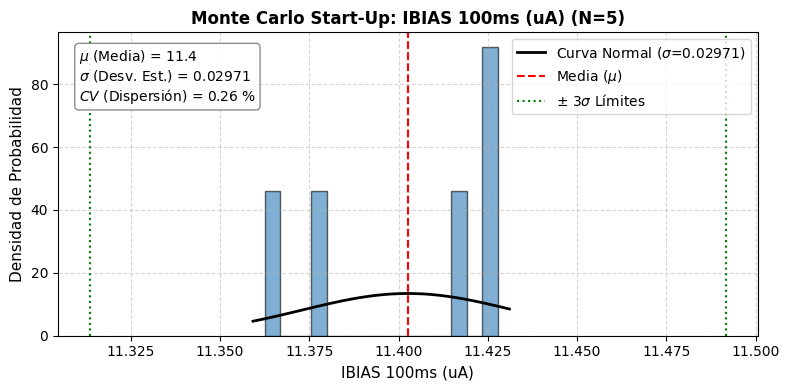

In [3]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import scipy.stats as stats
import os

# ==============================================================================
# 1. CARGAR Y EXTRAER LOS DATOS DEL SELF-BIAS
# ==============================================================================
ruta_archivo = "/headless/.xschem/simulations/self_bias_mc.txt"

if not os.path.exists(ruta_archivo):
    print(f"⚠️ Archivo no encontrado en: {ruta_archivo}")
    exit()

with open(ruta_archivo, 'r') as f:
    texto = f.read()

# Función actualizada: Ahora recibe el patrón Regex exacto para encontrar la variable
def extraer(patron, texto):
    encontrados = re.findall(patron, texto)
    valores = []
    for x in encontrados:
        try:
            valores.append(float(x))
        except ValueError:
            pass
    return valores

# Diccionario con patrones Regex para los 6 valores de interés del nuevo .control
candidatos = {
    'VR 100us (V)':      extraer(r"\[100us\]\s*VR\s*=\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", texto),

    
    'VR 1ms (V)':        extraer(r"\[1ms\]\s*VR\s*=\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", texto),

    
    'VR 100ms (V)':      extraer(r"\[100ms\]\s*VR\s*=\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", texto),
    'IBIAS 100ms (uA)':  extraer(r"\[100ms\].*?IBIAS\s*=\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", texto),
}

# Filtramos solo las variables que tengan datos válidos
datos_extraidos = {k: v for k, v in candidatos.items() if len(v) > 0}

if not datos_extraidos:
    print("⚠️ No se encontró ningún dato válido en el archivo de texto.")
    exit()

# Aseguramos que todas las listas tengan la misma longitud 
# (por si la simulación se interrumpió a la mitad)
longitud_minima = min(len(v) for v in datos_extraidos.values())
datos_extraidos = {k: v[:longitud_minima] for k, v in datos_extraidos.items()}

# Creamos el DataFrame
df_mc = pd.DataFrame(datos_extraidos)

print(f"✅ Muestras extraídas por variable:\n{df_mc.count()}\n")
print("--- Primeros 5 datos ---")
print(df_mc.head(5))
print("\n--- Resumen Estadístico ---")
print(df_mc.describe().loc[['count', 'mean', 'std', 'min', 'max']])

# ==============================================================================
# 2. FUNCIÓN PARA GRAFICAR HISTOGRAMAS Y CAMPANA DE GAUSS
# ==============================================================================
def graficar_gauss(df, columna):
    datos = df[columna].dropna()
    if len(datos) < 2:
        print(f"ℹ️ '{columna}' tiene menos de 2 datos (N={len(datos)}). Sube mc_runs para graficar.")
        return

    # Cálculos estadísticos
    mu = np.mean(datos)            # Media
    sigma = np.std(datos, ddof=1)  # Desviación estándar
    cv = (sigma / abs(mu)) * 100 if mu != 0 else 0  # Coeficiente de variación (%)

    # Configuración del gráfico
    fig, ax = plt.subplots(figsize=(8, 4))

    # Histograma de los datos reales
    count, bins, ignored = ax.hist(datos, bins=15, density=True, alpha=0.6, color='#2c7bb6', edgecolor='black')

    # Curva teórica de Gauss
    if sigma > 0:
        xmin, xmax = ax.get_xlim()
        x = np.linspace(xmin, xmax, 100)
        p = stats.norm.pdf(x, mu, sigma)
        ax.plot(x, p, 'k', linewidth=2, label=fr'Curva Normal ($\sigma$={sigma:.4g})')

    # Líneas verticales para Media y Límites de 3 Sigma
    ax.axvline(mu, color='red', linestyle='dashed', linewidth=1.5, label=fr'Media ($\mu$)')
    ax.axvline(mu - 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=fr'$\pm$ 3$\sigma$ Límites')
    ax.axvline(mu + 3*sigma, color='green', linestyle='dotted', linewidth=1.5)

    # Caja de texto con estadísticas (esquina superior izquierda)
    texto_estadisticas = '\n'.join((
        fr'$\mu$ (Media) = {mu:.4g}',
        fr'$\sigma$ (Desv. Est.) = {sigma:.4g}',
        fr'$CV$ (Dispersión) = {cv:.2f} %'
    ))
    
    props = dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray')
    ax.text(0.03, 0.95, texto_estadisticas, transform=ax.transAxes, fontsize=10,
            verticalalignment='top', bbox=props)

    # Formato visual
    ax.set_title(f'Monte Carlo Start-Up: {columna} (N={len(datos)})', fontsize=12, fontweight='bold')
    ax.set_xlabel(columna, fontsize=11)
    ax.set_ylabel('Densidad de Probabilidad', fontsize=11)
    
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3. GENERAR EL REPORTE VISUAL
# ==============================================================================
for columna in df_mc.columns:
    graficar_gauss(df_mc, columna)